##### 1 · Data exploration

A tour of everything in `data/raw/` before it goes into the optimizer: what each file holds,
how trustworthy each value is (sourced / derived / assumed), and the patterns that end up
driving the least-cost recipe.

Sections
1. File inventory
2. Ingredient composition (raw and as-fed)
3. Prices and cost per unit of nutrient
4. Price history 2023 to April 2026
5. Nutrient requirements (grower vs smolt)
6. Inclusion limits
7. Real-world benchmarks
8. Stock and inbound deliveries
9. Data quality checks
10. Takeaways

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Locate the project root (folder containing pyproject.toml) so the notebook runs from anywhere
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

from feedopt.data import AMINO_ACIDS, RAW_DIR, build_nutrient_matrix  # noqa: E402

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

# Chart style: recessive axes and grid, fixed categorical order
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "figure.dpi": 110,
})
print("Project root:", ROOT)

Project root: C:\Users\ajaos\Downloads\salmon-feed-optimizer\salmon-feed-optimizer


##### 1. File inventory

In [2]:
files = sorted(RAW_DIR.glob("*.csv"))
data = {f.stem: pd.read_csv(f) for f in files}
pd.DataFrame(
    {"rows": [len(d) for d in data.values()],
     "columns": [d.shape[1] for d in data.values()],
     "missing_cells": [int(d.isna().sum().sum()) for d in data.values()]},
    index=list(data.keys()),
)

,rows,columns,missing_cells
benchmarks,27,5,0
example_stock,8,4,0
inclusion_limits,9,4,0
ingredients_raw,15,29,4
price_history,11,8,0
prices,15,5,0
requirements,42,7,20


##### 2. Ingredient composition

`ingredients_raw.csv` follows Feedipedia conventions: dry matter (`dm`) is % as fed, the
proximates are % of dry matter, gross energy is MJ/kg DM, phosphorus is g/kg DM and amino acids
are % of crude protein. Fifteen ingredients across six categories.

In [3]:
raw = data["ingredients_raw"].set_index("ingredient")
raw[["category", "dm", "cp", "fat", "ash", "fibre", "starch", "ge", "p",
     "epa_dha_pct_fat", "adc_protein", "adc_energy"]]

,category,dm,cp,fat,ash,fibre,starch,ge,p,epa_dha_pct_fat,adc_protein,adc_energy
ingredient,,,,,,,,,,,,
fish_meal,marine,92.20,74.80,9.80,15.20,0.00,0.00,21.30,24.80,22,0.90,0.90
fish_oil,marine,99.90,0.00,99.50,0.00,0.00,0.00,39.00,0.00,25,0.00,0.96
soy_protein_concentrate,plant_protein,92.00,67.00,1.00,6.50,4.00,2.00,20.00,8.00,0,0.92,0.80
soybean_meal,plant_protein,88.00,52.60,1.80,7.10,6.80,5.70,19.70,7.10,0,0.88,0.70
maize_gluten_meal,plant_protein,90.00,67.20,2.90,2.10,1.20,17.60,23.10,4.00,0,0.96,0.83
wheat_gluten,plant_protein,92.00,82.00,1.50,1.00,0.50,10.00,23.00,2.00,0,0.98,0.92
pea_protein_concentrate,plant_protein,91.00,55.00,2.00,6.00,3.00,15.00,20.00,8.00,0,0.92,0.75
faba_bean_dehulled,plant_protein,85.90,31.00,1.30,4.10,8.50,43.20,18.70,4.60,0,0.85,0.50
wheat,carbohydrate,87.00,12.60,1.70,1.80,2.60,69.10,18.20,3.60,0,0.90,0.55


In [4]:
raw["category"].value_counts().rename("ingredients").to_frame()

,ingredients
category,
plant_protein,6
micro,4
marine,2
carbohydrate,1
vegetable_oil,1
novel,1


### How much of the composition data is actually measured?

Each row says whether its composition and its digestibility are sourced, partly sourced or
assumed. Digestibility is the weaker layer: most values are typical salmonid literature numbers.

In [5]:
status = pd.concat(
    [raw["composition_status"].value_counts().rename("composition"),
     raw["digestibility_status"].value_counts().rename("digestibility")],
    axis=1,
).fillna(0).astype(int)
status

,composition,digestibility
sourced,7,2
assumed,7,11
partly_sourced,1,0


In [6]:
raw[["composition_status", "digestibility_status"]].sort_values(
    ["composition_status", "digestibility_status"])

,composition_status,digestibility_status
ingredient,,
soy_protein_concentrate,assumed,assumed
wheat_gluten,assumed,assumed
pea_protein_concentrate,assumed,assumed
rapeseed_oil,assumed,assumed
algal_oil,assumed,assumed
monocalcium_phosphate,assumed,NaN
premix,assumed,NaN
fish_oil,partly_sourced,sourced
fish_meal,sourced,assumed


##### As-fed nutrient matrix

The optimizer works on an as-fed basis so a recipe is just inclusion shares that sum to 1.
`build_nutrient_matrix` does the conversion and applies the digestibility coefficients.

In [7]:
nm = build_nutrient_matrix(raw)
nm.drop(columns=AMINO_ACIDS)

,category,dm,crude_protein,crude_lipid,ash,fibre,starch,phosphorus,epa_dha,digestible_protein,digestible_energy
ingredient,,,,,,,,,,,
fish_meal,marine,0.92,68.97,9.04,14.01,0.00,0.00,2.29,1.99,62.07,17.67
fish_oil,marine,1.00,0.00,99.40,0.00,0.00,0.00,0.00,24.85,0.00,37.56
soy_protein_concentrate,plant_protein,0.92,61.64,0.92,5.98,3.68,1.84,0.74,0.00,56.71,14.72
soybean_meal,plant_protein,0.88,46.29,1.58,6.25,5.98,5.02,0.62,0.00,40.73,12.14
maize_gluten_meal,plant_protein,0.90,60.48,2.61,1.89,1.08,15.84,0.36,0.00,58.06,17.26
wheat_gluten,plant_protein,0.92,75.44,1.38,0.92,0.46,9.20,0.18,0.00,73.93,19.47
pea_protein_concentrate,plant_protein,0.91,50.05,1.82,5.46,2.73,13.65,0.73,0.00,46.05,13.65
faba_bean_dehulled,plant_protein,0.86,26.63,1.12,3.52,7.30,37.11,0.40,0.00,22.63,8.03
wheat,carbohydrate,0.87,10.96,1.48,1.57,2.26,60.12,0.31,0.00,9.87,8.71


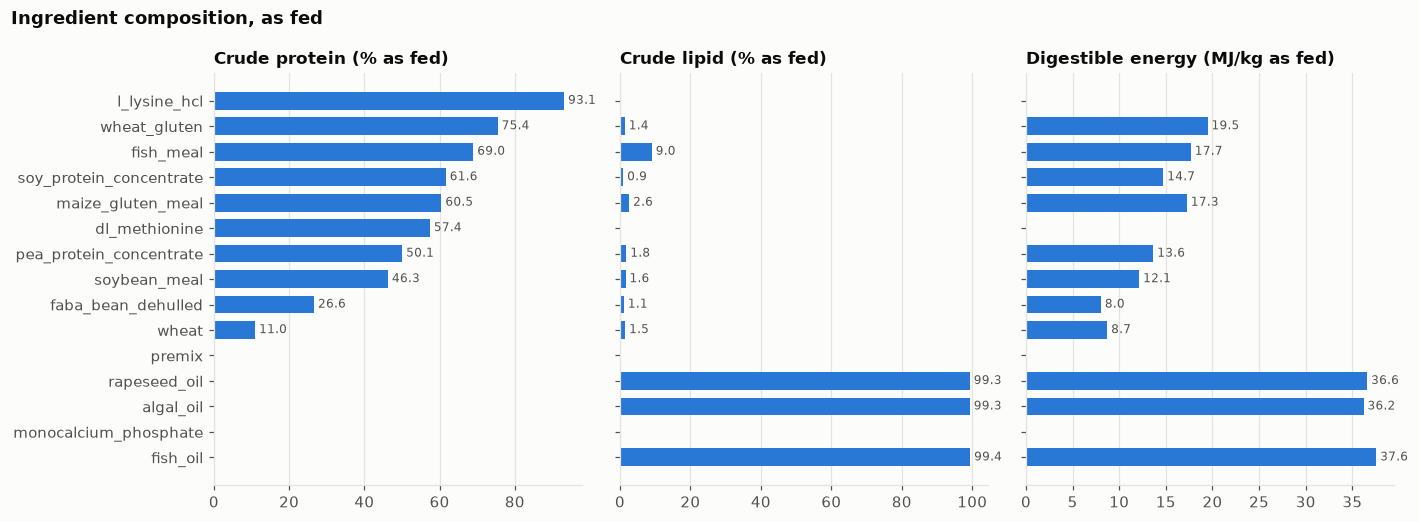

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), sharey=True)
order = nm.sort_values("crude_protein").index
for ax, col, label in zip(
    axes,
    ["crude_protein", "crude_lipid", "digestible_energy"],
    ["Crude protein (% as fed)", "Crude lipid (% as fed)", "Digestible energy (MJ/kg as fed)"],
):
    vals = nm.loc[order, col]
    ax.barh(order, vals, color=SERIES[0], height=0.7)
    ax.set_title(label, fontsize=11)
    ax.grid(axis="y", visible=False)
    for y, v in enumerate(vals):
        if v > 0:
            ax.text(v, y, f" {v:.1f}", va="center", fontsize=8, color=INK_2)
fig.suptitle("Ingredient composition, as fed", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

##### Essential amino acids

Amino acids as % as fed. Fish meal and the protein concentrates carry most of them; the free
lysine and methionine products are near-pure single amino acids.

In [9]:
aa = nm[AMINO_ACIDS]
aa = aa[aa.sum(axis=1) > 0].sort_values("lys", ascending=False)
aa

,lys,met,thr,trp,arg,his,ile,leu,phe,val
ingredient,,,,,,,,,,
l_lysine_hcl,78.80,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
fish_meal,5.17,1.93,2.83,0.69,4.48,1.66,2.90,4.97,2.69,3.45
soy_protein_concentrate,3.82,0.86,2.34,0.86,4.50,1.66,2.84,4.68,3.14,2.96
pea_protein_concentrate,3.60,0.50,1.85,0.45,4.25,1.20,2.20,4.00,2.65,2.40
soybean_meal,2.87,0.65,1.76,0.65,3.38,1.25,2.13,3.52,2.36,2.22
faba_bean_dehulled,1.68,0.21,0.93,0.21,2.37,0.67,1.09,1.89,1.09,1.22
wheat_gluten,1.21,1.28,1.96,0.75,2.72,1.58,2.72,5.13,3.85,3.02
maize_gluten_meal,1.03,1.45,2.00,0.30,1.81,1.21,2.42,9.62,3.69,2.72
wheat,0.32,0.18,0.32,0.13,0.52,0.25,0.37,0.71,0.49,0.47


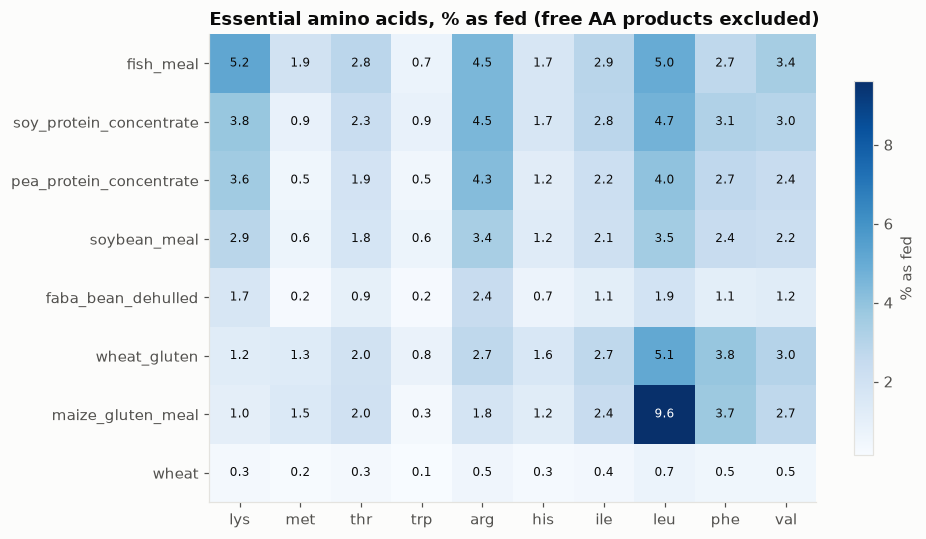

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
shown = aa.drop(index=[i for i in ["l_lysine_hcl", "dl_methionine"] if i in aa.index])
im = ax.imshow(shown.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(AMINO_ACIDS)), AMINO_ACIDS)
ax.set_yticks(range(len(shown)), shown.index)
ax.grid(False)
for (i, j), v in np.ndenumerate(shown.values):
    ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
            color="white" if v > shown.values.max() * 0.55 else INK)
ax.set_title("Essential amino acids, % as fed (free AA products excluded)")
fig.colorbar(im, ax=ax, shrink=0.8, label="% as fed")
fig.tight_layout()
plt.show()

##### 3. Prices

In [11]:
prices = data["prices"].set_index("ingredient")
prices[["price_usd_per_t", "basis", "price_status"]].sort_values("price_usd_per_t", ascending=False)

,price_usd_per_t,basis,price_status
ingredient,,,
algal_oil,12000,Assumption,assumed
dl_methionine,3500,Assumption,assumed
fish_oil,3500,Assumption,assumed
premix,3000,Assumption,assumed
fish_meal,1837,March 2026 monthly average,sourced
l_lysine_hcl,1800,Assumption,assumed
wheat_gluten,1800,Assumption,assumed
pea_protein_concentrate,1400,Assumption,assumed
rapeseed_oil,1304,March 2026 monthly average,sourced


In [12]:
prices["price_status"].value_counts().rename("ingredients").to_frame()

,ingredients
price_status,
assumed,7
sourced,4
derived,4


##### Cost per unit of nutrient

The list price per tonne means little on its own. What matters to the LP is what each ingredient
costs per kg of the nutrient it supplies. This is a rough single-nutrient view; the optimizer
values all nutrients at once.

In [13]:
p = prices["price_usd_per_t"]
unit = pd.DataFrame({
    "price_usd_t": p,
    "usd_per_kg_digestible_protein": p / (nm["digestible_protein"] * 10),
    "usd_per_GJ_digestible_energy": p / nm["digestible_energy"],
    "usd_per_kg_epa_dha": p / (nm["epa_dha"] * 10),
}).replace(np.inf, np.nan)
unit.sort_values("usd_per_kg_digestible_protein")

,price_usd_t,usd_per_kg_digestible_protein,usd_per_GJ_digestible_energy,usd_per_kg_epa_dha
ingredient,,,,
soybean_meal,404,0.99,33.29,NaN
maize_gluten_meal,640,1.10,37.09,NaN
faba_bean_dehulled,350,1.55,43.58,NaN
soy_protein_concentrate,1010,1.78,68.61,NaN
l_lysine_hcl,1800,1.93,NaN,NaN
wheat_gluten,1800,2.43,92.46,NaN
wheat,247,2.50,28.36,NaN
fish_meal,1837,2.96,103.93,92.41
pea_protein_concentrate,1400,3.04,102.56,NaN


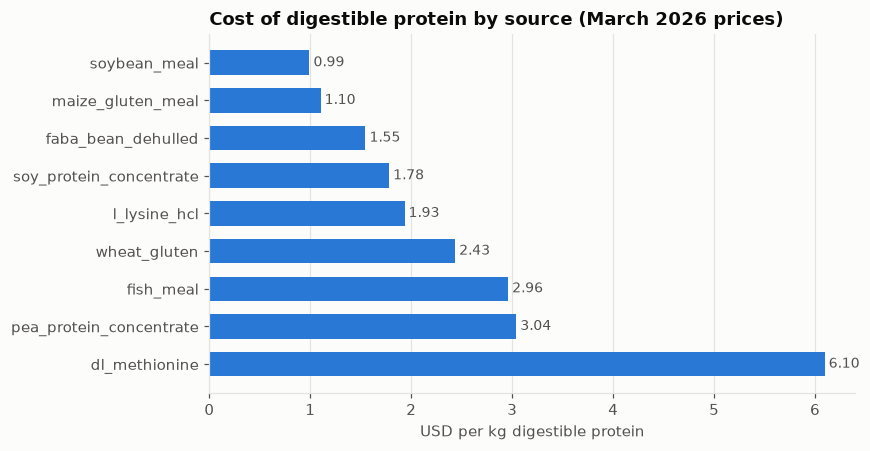

In [14]:
dp = unit["usd_per_kg_digestible_protein"].dropna()
dp = dp[nm.loc[dp.index, "digestible_protein"] > 20].sort_values()  # protein sources only

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(dp.index, dp.values, color=SERIES[0], height=0.65)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
for y, v in enumerate(dp.values):
    ax.text(v, y, f" {v:.2f}", va="center", fontsize=9, color=INK_2)
ax.set_xlabel("USD per kg digestible protein")
ax.set_title("Cost of digestible protein by source (March 2026 prices)")
fig.tight_layout()
plt.show()

##### Omega-3: fish oil vs algal oil

EPA+DHA has only two sources here. The ratio of their cost per kg of EPA+DHA tells you roughly
how far fish oil must rise before algal oil wins, ignoring the energy fish oil also supplies.

In [15]:
o3 = unit.loc[["fish_oil", "fish_meal", "algal_oil"], ["price_usd_t", "usd_per_kg_epa_dha"]]
o3["epa_dha_pct_as_fed"] = nm.loc[o3.index, "epa_dha"]
o3

,price_usd_t,usd_per_kg_epa_dha,epa_dha_pct_as_fed
ingredient,,,
fish_oil,3500,14.08,24.85
fish_meal,1837,92.41,1.99
algal_oil,12000,24.17,49.65


In [16]:
fo, ao = nm.loc["fish_oil", "epa_dha"], nm.loc["algal_oil", "epa_dha"]
breakeven = p["algal_oil"] * fo / ao
print(f"Fish oil EPA+DHA: {fo:.1f}% as fed, algal oil: {ao:.1f}% as fed")
print(f"Fish oil price at equal cost per kg EPA+DHA: {breakeven:,.0f} USD/t "
      f"(assumed base price {p['fish_oil']:,.0f})")

Fish oil EPA+DHA: 24.9% as fed, algal oil: 49.7% as fed
Fish oil price at equal cost per kg EPA+DHA: 6,006 USD/t (assumed base price 3,500)


##### 4. Price history (World Bank Pink Sheet)

In [17]:
hist = data["price_history"]
hist

,period,period_type,fish_meal,soybean_meal,soybean_oil,maize,wheat_us_srw,source
0,2023,annual,1815,541,1119,252.70,257.70,World Bank Pink Sheet May 2026
1,2024,annual,1699,442,1022,190.60,230.90,World Bank Pink Sheet May 2026
2,2025,annual,1706,366,1140,203.20,219.60,World Bank Pink Sheet May 2026
3,2025Q1,quarterly,1606,365,1043,214.20,233.90,World Bank Pink Sheet May 2026
4,2025Q2,quarterly,1678,360,1154,205.00,219.40,World Bank Pink Sheet May 2026
5,2025Q3,quarterly,1745,349,1237,191.60,206.00,World Bank Pink Sheet May 2026
6,2025Q4,quarterly,1796,389,1125,201.90,219.20,World Bank Pink Sheet May 2026
7,2026Q1,quarterly,1832,393,1310,208.90,232.50,World Bank Pink Sheet May 2026
8,2026-02,monthly,1840,391,1282,209.60,232.40,World Bank Pink Sheet May 2026
9,2026-03,monthly,1837,404,1493,212.70,247.40,World Bank Pink Sheet May 2026


In [18]:
COMMODITIES = ["fish_meal", "soybean_meal", "soybean_oil", "maize", "wheat_us_srw"]
annual = hist[hist["period_type"] == "annual"].set_index("period")[COMMODITIES]
change = (annual.loc["2025"] / annual.loc["2023"] - 1).mul(100).rename("change_2023_to_2025_pct")
pd.concat([annual.T, change], axis=1)

,2023,2024,2025,change_2023_to_2025_pct
fish_meal,"1,815.00","1,699.00","1,706.00",-6.01
soybean_meal,541.00,442.00,366.00,-32.35
soybean_oil,"1,119.00","1,022.00","1,140.00",1.88
maize,252.70,190.60,203.20,-19.59
wheat_us_srw,257.70,230.90,219.60,-14.78


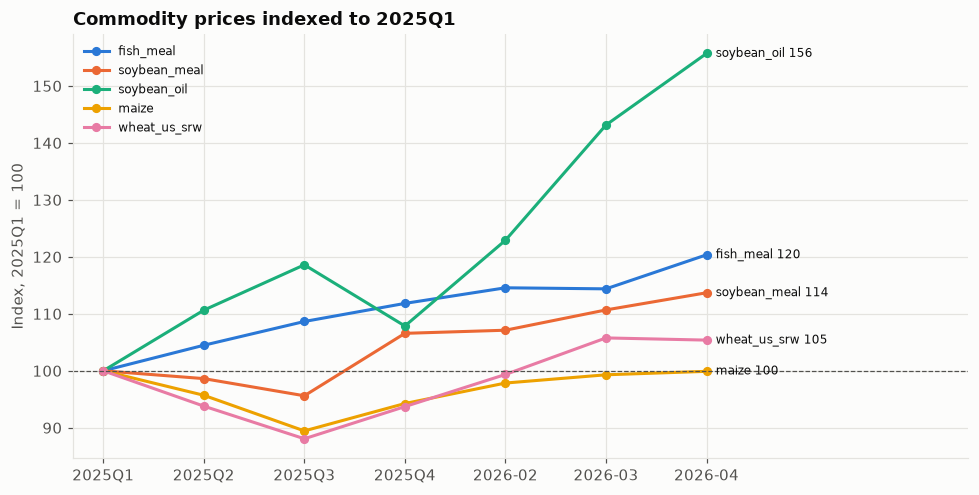

In [19]:
seq = hist[hist["period_type"].isin(["quarterly", "monthly"])].copy()
# Keep quarterly through 2025Q4, then the 2026 months so time moves forward without overlap
seq = pd.concat([seq[(seq.period_type == "quarterly") & seq.period.str.startswith("2025")],
                 seq[seq.period_type == "monthly"]]).set_index("period")[COMMODITIES]
indexed = seq / seq.iloc[0] * 100

fig, ax = plt.subplots(figsize=(9, 4.6))
for i, c in enumerate(COMMODITIES):
    ax.plot(indexed.index, indexed[c], color=SERIES[i], marker="o", markersize=5, label=c)
    ax.annotate(f"{c} {indexed[c].iloc[-1]:.0f}", (len(indexed) - 1, indexed[c].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=INK)
ax.axhline(100, color=INK_2, linewidth=0.8, linestyle="--")
ax.set_ylabel("Index, 2025Q1 = 100")
ax.set_xlim(-0.3, len(indexed) + 1.6)
ax.legend(loc="upper left", frameon=False, fontsize=8)
ax.set_title("Commodity prices indexed to 2025Q1")
fig.tight_layout()
plt.show()

Note that the history covers five commodities. Fish oil, algal oil, the protein concentrates and
the additives have no free price series, so in the historical scenario they stay fixed or are
derived from these (for example SPC = 2.5 × soybean meal).

##### 5. Nutrient requirements (FAO AFFRIS)

In [20]:
req = data["requirements"]
wide = req.pivot_table(index=["nutrient", "bound", "unit"], columns="profile", values="value").reset_index()
wide["smolt_minus_grower"] = wide["smolt_100_250g"] - wide["grower_1_2kg"]
wide

profile,nutrient,bound,unit,grower_1_2kg,smolt_100_250g,smolt_minus_grower
0,arg,min,% DM,1.60,1.60,0.00
1,ash,max,% DM,9.00,11.00,2.00
2,crude_lipid,max,% DM,35.00,32.00,-3.00
3,crude_lipid,min,% DM,30.00,26.00,-4.00
4,crude_protein,min,% DM,40.00,46.00,6.00
5,digestible_energy,min,MJ/kg DM,21.00,19.00,-2.00
6,dp_de_ratio,min,g DP/MJ DE,16.20,20.40,4.20
7,epa_dha,min,% DM,1.00,1.00,0.00
8,fibre,max,% DM,2.00,2.00,0.00
9,his,min,% DM,0.70,0.70,0.00


In [21]:
req["source"].str.contains("assumed", case=False).groupby(req["profile"]).sum().rename(
    "rows_marked_assumed").to_frame()

,rows_marked_assumed
profile,
grower_1_2kg,2
smolt_100_250g,2


Smolt feed asks for more protein (46 vs 40% DM) and a much higher DP/DE ratio (20.4 vs 16.2),
with a little less fat and energy. The amino acid minimums are the same for both profiles.

##### 6. Inclusion limits

In [22]:
data["inclusion_limits"].set_index("ingredient")

,min_pct,max_pct,reason
ingredient,,,
soybean_meal,0,5.00,Higher levels cause soybean meal induced enter...
faba_bean_dehulled,0,10.00,Antinutrients and starch (practical limit assu...
maize_gluten_meal,0,12.00,Pigment and palatability (practical limit assu...
wheat_gluten,0,15.00,Pellet texture (practical limit assumed)
pea_protein_concentrate,0,15.00,Antinutrients (practical limit assumed)
l_lysine_hcl,0,0.50,Crystalline amino acid ceiling (assumed)
dl_methionine,0,0.30,Crystalline amino acid ceiling (assumed)
monocalcium_phosphate,0,3.00,Mineral ceiling (assumed)
premix,2,2.00,Fixed vitamin and mineral premix (assumed)


In [23]:
unlimited = sorted(set(raw.index) - set(data["inclusion_limits"]["ingredient"]))
print("Ingredients with no practical limit (0 to 100%):", ", ".join(unlimited))

Ingredients with no practical limit (0 to 100%): algal_oil, fish_meal, fish_oil, rapeseed_oil, soy_protein_concentrate, wheat


##### 7. Real-world benchmarks

In [24]:
bench = data["benchmarks"]
bench.pivot_table(index="metric", columns="benchmark", values="value")

benchmark,fao_marine_grower,mowi_2025,norway_1990,norway_2020,skretting_protec_4_5mm
metric,,,,,
arg,NaN,NaN,NaN,NaN,3.30
ash,NaN,NaN,NaN,NaN,8.00
carbohydrate,7.40,NaN,NaN,13.00,NaN
crude_lipid,30.00,NaN,NaN,NaN,22.00
crude_protein,44.00,NaN,NaN,NaN,47.42
dry_matter,NaN,NaN,NaN,NaN,93.00
fish_meal,28.80,16.00,65.00,12.00,NaN
fish_oil,25.80,11.00,24.00,10.00,NaN
gross_energy,NaN,NaN,NaN,NaN,22.10


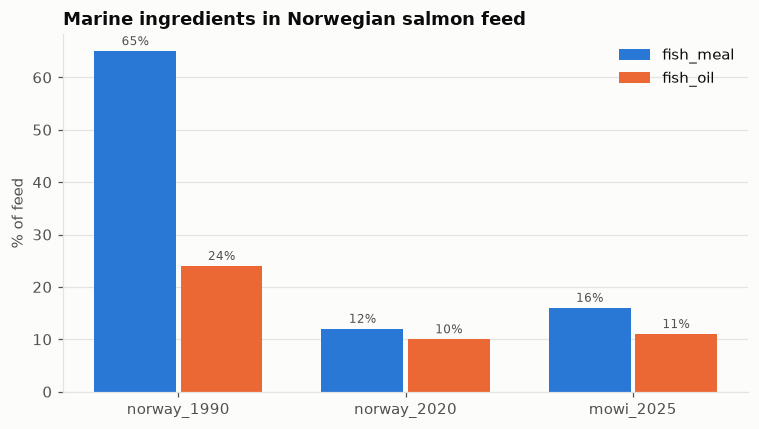

In [25]:
marine = bench[bench["metric"].isin(["fish_meal", "fish_oil"])
               & bench["benchmark"].isin(["norway_1990", "norway_2020", "mowi_2025"])]
m = marine.pivot(index="benchmark", columns="metric", values="value").loc[
    ["norway_1990", "norway_2020", "mowi_2025"]]

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(m))
w = 0.36
for k, (col, color) in enumerate(zip(["fish_meal", "fish_oil"], SERIES)):
    bars = ax.bar(x + (k - 0.5) * (w + 0.02), m[col], width=w, color=color, label=col)
    ax.bar_label(bars, fmt="%.0f%%", fontsize=8, color=INK_2, padding=2)
ax.set_xticks(x, m.index)
ax.grid(axis="x", visible=False)
ax.set_ylabel("% of feed")
ax.legend(frameon=False)
ax.set_title("Marine ingredients in Norwegian salmon feed")
fig.tight_layout()
plt.show()

##### 8. Stock and inbound deliveries (illustrative)

In [26]:
stock = data["example_stock"].set_index("ingredient")[["stock_t", "inbound_t"]]
stock["available_t"] = stock.sum(axis=1)
PRODUCTION_T = 20_000  # same monthly production as scripts/run_all.py
stock["max_inclusion_pct_at_20kt"] = stock["available_t"] / PRODUCTION_T * 100
stock.sort_values("max_inclusion_pct_at_20kt")

,stock_t,inbound_t,available_t,max_inclusion_pct_at_20kt
ingredient,,,,
algal_oil,200,0,200,1.00
fish_oil,250,0,250,1.25
soybean_meal,800,500,1300,6.50
fish_meal,1500,1000,2500,12.50
maize_gluten_meal,1500,1200,2700,13.50
wheat,2000,1500,3500,17.50
rapeseed_oil,3000,2500,5500,27.50
soy_protein_concentrate,4000,3000,7000,35.00


At 20,000 t/month, fish oil stock covers only about 1.25% of the recipe and algal oil 1%.
That's what forces the supply-shock re-formulation in the planning scenario.

##### 9. Data quality checks

In [27]:
ing = set(raw.index)
checks = {
    "every ingredient has a price": ing <= set(prices.index),
    "every priced item is an ingredient": set(prices.index) <= ing,
    "limits only reference known ingredients": set(data["inclusion_limits"]["ingredient"]) <= ing,
    "stock only references known ingredients": set(stock.index) <= ing,
    "no missing numeric composition": not raw.select_dtypes("number").isna().any().any(),
    "dm between 0 and 100": raw["dm"].between(0, 100).all(),
    "proximates (cp+fat+ash+fibre+starch) <= 100% DM":
        (raw[["cp", "fat", "ash", "fibre", "starch"]].sum(axis=1) <= 100.5).all(),
    "digestibility coefficients in [0, 1]":
        raw[["adc_protein", "adc_energy"]].stack().between(0, 1).all(),
    "both requirement profiles have the same nutrients":
        req.groupby("profile")[["nutrient", "bound"]].apply(lambda d: tuple(sorted(map(tuple, d.values)))).nunique() == 1,
}
pd.Series(checks, name="passes").to_frame()

,passes
every ingredient has a price,True
every priced item is an ingredient,True
limits only reference known ingredients,True
stock only references known ingredients,True
no missing numeric composition,True
dm between 0 and 100,True
proximates (cp+fat+ash+fibre+starch) <= 100% DM,True
"digestibility coefficients in [0, 1]",True
both requirement profiles have the same nutrients,True


In [28]:
has_aa = raw[raw[AMINO_ACIDS].sum(axis=1) > 0]
dup_aa = has_aa.groupby(has_aa[AMINO_ACIDS].apply(tuple, axis=1)).apply(lambda g: list(g.index))
shared = [g for g in dup_aa if len(g) > 1]
print("Ingredients sharing an identical amino acid profile (copied, not measured):")
for g in shared:
    print("  -", ", ".join(g))

Ingredients sharing an identical amino acid profile (copied, not measured):
  - soy_protein_concentrate, soybean_meal


##### 10. Takeaways

_Filled in after running the notebook._